# Joint multi-omics deconvolution: Tonsil RNA and protein

**Author: Su Xu**

Learn a shared spatial mixture from paired measurements at the same locations. The Tonsil example contains **4,908 matched spots, 2,000 RNA genes and 35 protein measurements**, fitted reference-free with $K=11$. Twenty RNA–protein feature pairs constrain the cross-assay profile penalty; every input feature remains in reconstruction.

Assays are balanced to equal total contribution before concatenation. One $P$ is shared across modalities. A quadratic penalty encourages agreement of matched-feature enrichment profiles after adjustment for each feature's observed abundance, while modality deviations allow disagreement. The joint objective combines Poisson KL, within-section graph TV and the profile-coupling penalty. Here the penalty coefficient is 10 and spatial weight is 0.05. Protein values are the prepared official isotype-normalized nonnegative measurements, not log-transformed counts.

The saved joint result is a complete reproduction fit. Component numbers can permute between fits; biological identities should be established from profiles and independent annotations.

## 1. Set up

Install spDecon using the repository installation instructions, then run this notebook from the cloned repository. The first data-loading cell downloads the versioned data bundle if needed. Saved fits make all plots available on a CPU. Full reference-free training uses the pinned CUDA environment. The saved results are complete fits, not shortened runs. `RUN_FIT=True` executes the full fitting code below; deterministic kernels and a fixed seed support repeatable new fits. Small differences from historical GPU runs may remain.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tutorials.common import dataset, correlation, align, spatial, pies, legend, save_figure, save_table
from spDecon.reproducibility import set_seed
set_seed(0, deterministic=True)
# The published outputs inspect complete fitted results. Enable full training explicitly.
RUN_FIT = False


## 2. Load paired assays and matched features

Spot IDs and order must match in both assays. For new data, a feature-link table identifies corresponding RNA and protein measurements; it does not require discarding unmatched features.

In [2]:
path,data=dataset("tonsil")
modalities={name:np.array(data["Y_"+name],dtype=float,order="F") for name in ["RNA","protein"]}
links={name:data["links_"+name].tolist() for name in modalities}
print({name:y.shape for name,y in modalities.items()})
display(pd.DataFrame({name:data["genes_"+name][links[name]] for name in modalities}))

{'RNA': (4908, 2000), 'protein': (4908, 35)}


,RNA,protein
0,RNA::ENSG00000177575,PROT::CD163
1,RNA::ENSG00000117322,PROT::CR2
2,RNA::ENSG00000026025,PROT::VIM
3,RNA::ENSG00000196092,PROT::PAX5
4,RNA::ENSG00000115884,PROT::SDC1
5,RNA::ENSG00000171791,PROT::BCL2
6,RNA::ENSG00000177455,PROT::CD19
7,RNA::ENSG00000107796,PROT::ACTA2
8,RNA::ENSG00000140678,PROT::ITGAX
9,RNA::ENSG00000160683,PROT::CXCR5


## 3. Fit the joint model

All 4,908 locations contribute to fitting. No pathology labels enter initialization, the objective or feature pairing. The cap is 20,000 iterations; the full saved joint reproduction stopped at 19,000.

In [3]:
from spDecon.multiomics import fit_multiomics
if RUN_FIT:
    result=fit_multiomics(modalities,11,links=links,edges=data["edges"],
                         eta=10.,spatial_weight=.05,random_state=0,device="cuda",max_iter=20000)
    p,b=result.proportions,result.profiles
    display(result.diagnostics)
else:
    fitted=np.load(path/"joint.npz")
    p,b=fitted["P"],fitted["B"]
print("Shared spot weights:",p.shape,"Concatenated assay profiles:",b.shape)

Shared spot weights: (4908, 11) Concatenated assay profiles: (11, 2035)


## 4. Display the eleven shared spatial components

All maps use the same 0–1 weight scale. The first panel summarizes the dominant component; the remaining panels display the full continuous contribution for each component.

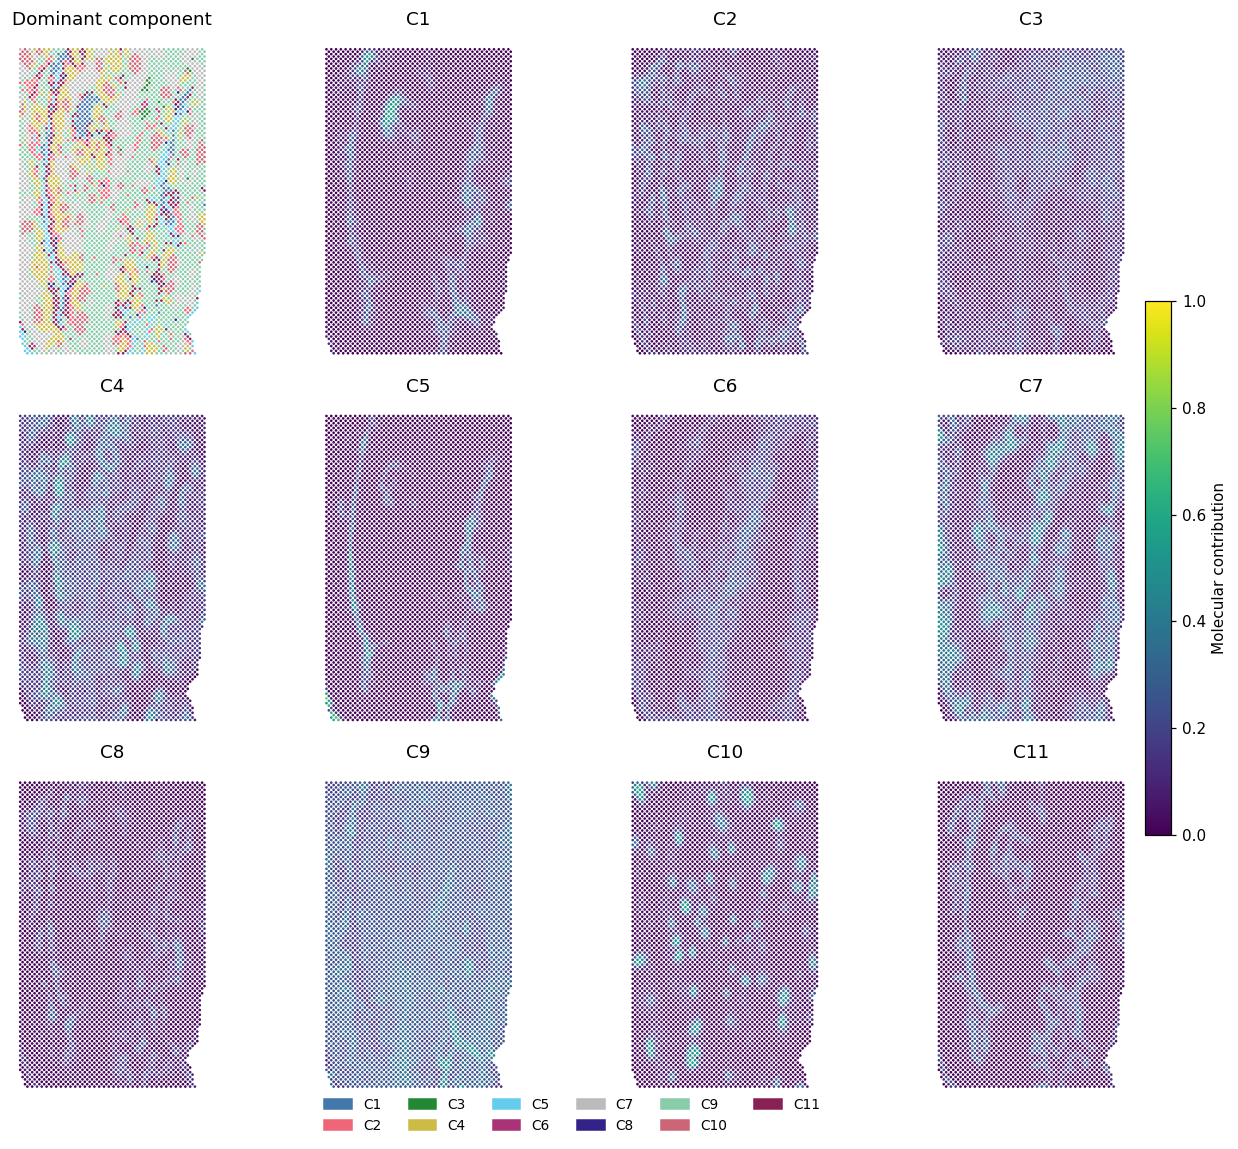

In [4]:
fig,axes=plt.subplots(3,4,figsize=(12,10),layout="constrained")
spatial(axes[0,0],data["coordinates"],p.argmax(axis=1),"Dominant component",categorical=True,size=3)
for k,ax in enumerate(axes.ravel()[1:]):
    art=spatial(ax,data["coordinates"],p[:,k],f"C{k+1}",size=3)
fig.colorbar(art,ax=axes.ravel().tolist(),label="Molecular contribution",shrink=.5,pad=.01)
legend(fig,[f"C{k+1}" for k in range(11)],columns=6,y=-.035)
save_figure(fig,"tonsil_joint_structure")

## 5. Read the germinal-center comparison

The pathology comparison uses 391 germinal-center (GC) and 4,515 other labelled spots; two locations are unlabelled. The table uses the manuscript component identities after profile alignment. It compares complete independent RNA, independent protein and joint fits. Mean contribution and enrichment are descriptive, not cell-count fractions or spot-independent significance tests.

In [5]:
report=pd.read_csv(path/"reproduction_metrics.csv")
display(report.loc[report.version.eq("rerun"),
    ["arm","aligned_component","mean_P_GC","mean_P_Other","GC_to_Other","AUROC","n_GC","n_Other"]])
out=ROOT/"outputs/tonsil";out.mkdir(parents=True,exist_ok=True)
pd.DataFrame(p,index=data["spots"],columns=[f"C{k+1}" for k in range(11)]).to_csv(out/"joint_weights.csv")

,arm,aligned_component,mean_P_GC,mean_P_Other,GC_to_Other,AUROC,n_GC,n_Other
1,RNA,8,0.233371,0.023666,9.860953,0.968974,391,4515
3,protein,7,0.155327,0.023196,6.696182,0.972007,391,4515
5,joint,10,0.320929,0.036304,8.840116,0.976184,391,4515


## 6. Adapt the analysis

Use the same spot ordering and matched-feature names for your own paired assays. To run an assay-only control, pass a one-entry dictionary with `eta=0` and no links; the manuscript controls allow up to 80,000 iterations. For a reference-based paired model, pass one harmonized reference per assay, with identical reference-type order, and use `eta=0` because fixed profiles have no learned modality deviations.